# Exploring the data and the results

What the MovieLens 100K ratings look like, why recommending from them is hard, and how the three models compare.

Run `python scripts/download_data.py` first, and `python -m rec_engine.train` and `python -m rec_engine.baselines` if `reports/metrics.json` is missing. Every number below is computed in this notebook or read from `reports/metrics.json`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from rec_engine.data_loader import dataset_stats, load_ratings

# One quiet look for every chart: off-white, thin lines, no frame on top or right.
plt.rcParams.update({
    "figure.facecolor": "#FAFAF8", "axes.facecolor": "#FAFAF8", "savefig.facecolor": "#FAFAF8",
    "axes.edgecolor": "#BDBDB8", "axes.labelcolor": "#111111", "text.color": "#111111",
    "xtick.color": "#6B6B66", "ytick.color": "#6B6B66", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#E4E4DF", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "regular", "axes.titlelocation": "left",
    "figure.dpi": 110,
})
INK, GREY, LIGHT = "#111111", "#9A9A94", "#D9D9D3"

ratings = load_ratings(ROOT / "data/raw/ml-100k/u.data")
stats = dataset_stats(ratings)
stats

{'n_users': 943,
 'n_items': 1682,
 'n_ratings': 100000,
 'sparsity': 0.9369533063577546}

## The shape of the data

There are about 1.6 million possible user and film pairs (943 users times 1,682 films), and only 100,000 of them have a rating. That gap is the whole problem: the model has to guess the rest.

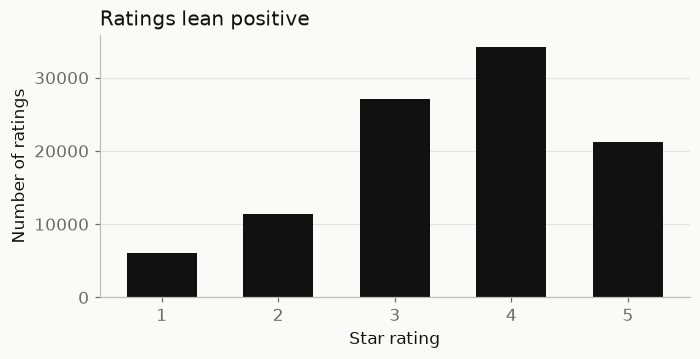

Share of ratings that are 4 or 5 stars: 55.4%
Sparsity (share of user and film pairs with no rating): 0.9370


In [2]:
counts = ratings["rating"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.bar(counts.index, counts.values, color=INK, width=0.6)
ax.set_xlabel("Star rating")
ax.set_ylabel("Number of ratings")
ax.set_title("Ratings lean positive")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
print(f"Share of ratings that are 4 or 5 stars: {counts.loc[[4, 5]].sum() / counts.sum():.1%}")
print(f"Sparsity (share of user and film pairs with no rating): {stats['sparsity']:.4f}")

## The long tail

Most of the ratings go to a minority of popular films, and many films have only a handful. A model that simply recommends popular films looks good on accuracy and useless on variety. This is why the repo reports catalogue coverage as well as precision and recall.

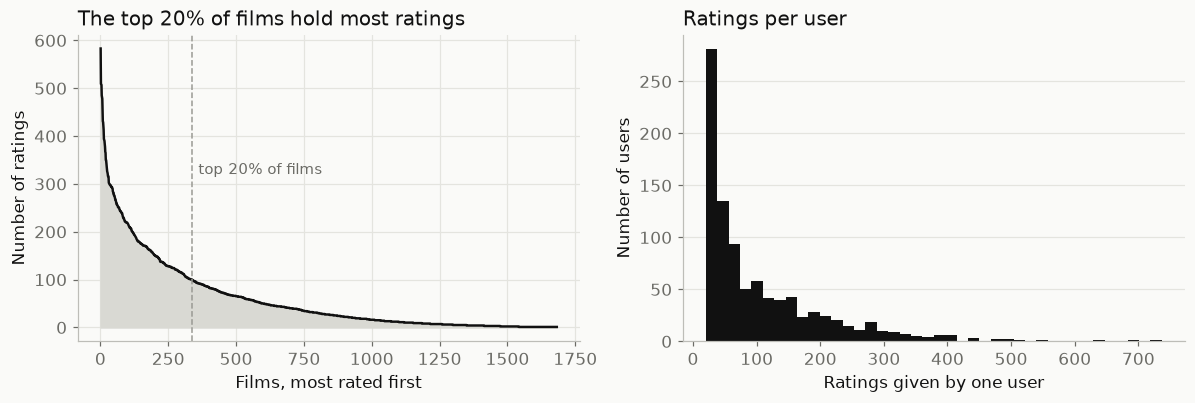

The top 20% of films hold 64.6% of all ratings.
333 of 1682 films have fewer than 5 ratings.
Median ratings per user: 65. Minimum: 20.


In [3]:
per_item = ratings.groupby("item_id").size().sort_values(ascending=False).to_numpy()
per_user = ratings.groupby("user_id").size().to_numpy()

top_20_pct = round(len(per_item) * 0.2)
share_top = per_item[:top_20_pct].sum() / per_item.sum()
few = (per_item < 5).sum()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))

ax1.fill_between(np.arange(1, len(per_item) + 1), per_item, color=LIGHT)
ax1.plot(np.arange(1, len(per_item) + 1), per_item, color=INK, linewidth=1.6)
ax1.axvline(top_20_pct, color=GREY, linestyle="--", linewidth=1)
ax1.text(top_20_pct + 25, per_item.max() * 0.55, "top 20% of films", color="#6B6B66", fontsize=10)
ax1.set_xlabel("Films, most rated first")
ax1.set_ylabel("Number of ratings")
ax1.set_title("The top 20% of films hold most ratings")

ax2.hist(per_user, bins=40, color=INK)
ax2.set_xlabel("Ratings given by one user")
ax2.set_ylabel("Number of users")
ax2.set_title("Ratings per user")
ax2.grid(axis="x", visible=False)

plt.tight_layout()
plt.savefig(ROOT / "docs/images/long-tail.png", dpi=160, bbox_inches="tight")
plt.show()

print(f"The top 20% of films hold {share_top:.1%} of all ratings.")
print(f"{few} of {len(per_item)} films have fewer than 5 ratings.")
print(f"Median ratings per user: {int(np.median(per_user))}. Minimum: {per_user.min()}.")

## How the models compare

Three models, scored the same way: each user is ranked against the full 1,682-film catalogue, and a film counts as relevant when the user rated it 4 or more in the held-out 20%.

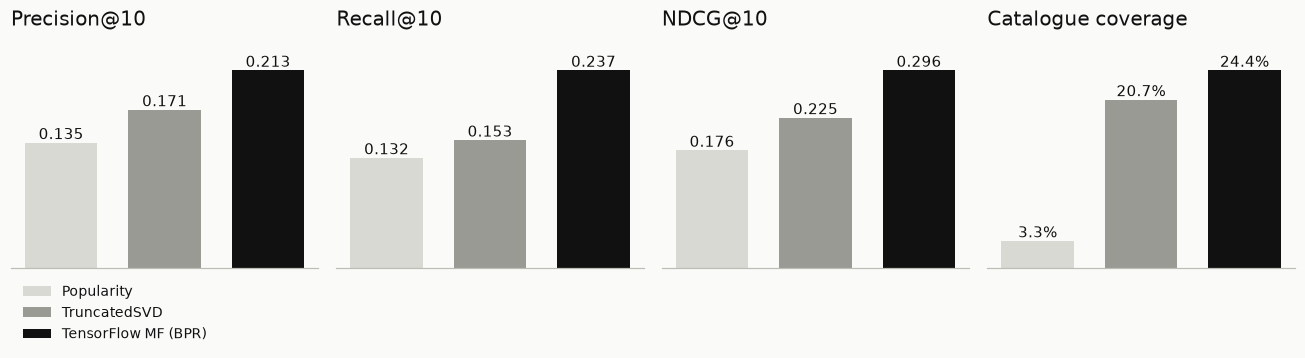

In [4]:
metrics = json.loads((ROOT / "reports/metrics.json").read_text(encoding="utf-8"))
models = [("popularity", "Popularity"), ("truncated_svd", "TruncatedSVD"), ("tf_mf", "TensorFlow MF (BPR)")]
panels = [("precision_at_k", "Precision@10"), ("recall_at_k", "Recall@10"), ("ndcg_at_k", "NDCG@10"), ("catalogue_coverage", "Catalogue coverage")]

fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
for ax, (key, title) in zip(axes, panels):
    values = [metrics[m][key] for m, _ in models]
    bars = ax.bar(range(3), values, color=[LIGHT, GREY, INK], width=0.7)
    for bar, v in zip(bars, values):
        label = f"{v:.1%}" if key == "catalogue_coverage" else f"{v:.3f}"
        ax.text(bar.get_x() + bar.get_width() / 2, v, label, ha="center", va="bottom", fontsize=9.5)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_ylim(0, max(values) * 1.18)
    ax.grid(axis="x", visible=False)
    ax.yaxis.set_visible(False)
    ax.spines["left"].set_visible(False)
axes[0].legend(bars, [name for _, name in models], loc="upper left", frameon=False, fontsize=9, bbox_to_anchor=(0, -0.02), ncol=1)
plt.tight_layout()
plt.savefig(ROOT / "docs/images/model-comparison.png", dpi=160, bbox_inches="tight")
plt.show()

In [5]:
print(f"{'Model':<22}{'RMSE':>8}{'P@10':>9}{'R@10':>9}{'NDCG@10':>10}{'Coverage':>10}")
for key, name in models:
    m = metrics[key]
    print(f"{name:<22}{m['rmse']:>8.3f}{m['precision_at_k']:>9.3f}{m['recall_at_k']:>9.3f}{m['ndcg_at_k']:>10.3f}{m['catalogue_coverage']:>10.1%}")

Model                     RMSE     P@10     R@10   NDCG@10  Coverage
Popularity               1.126    0.135    0.132     0.176      3.3%
TruncatedSVD             1.040    0.171    0.153     0.225     20.7%
TensorFlow MF (BPR)      2.561    0.213    0.237     0.296     24.4%


## Reading the table

The TensorFlow model ranks best on every ranking metric and recommends from a wider slice of the catalogue. Its RMSE is the worst of the three, and that is expected: it is trained to put liked films in the right order (a ranking loss called BPR), not to predict the exact star rating. If your product shows a ranked list, ranking quality is the number to watch.